# Равновесный $\delta$ в магнитном кольце с тонким ВЧ

Одна тетрадь, девять шагов. Полость стоит в `lat.elements` и включена с первого шага. Полные рисунки на 12 000 оборотов считаются скриптом `scripts/run_v08.jl` и лежат в `note/figs`. Здесь короткие прогоны и те же выводы.

Модели: **M1** формула, **M2** нормальная форма произведения Ли, **M3** полином степени 3, **M4** точный интегратор.

## Кольцо Bell

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using EquilibriumEnergy, Bell, Plots, Printf, Statistics
gr(); default(fontfamily = "sans-serif", framestyle = :box, grid = true)
const OPTIM = raw"C:\GIT_REPOS\SCT_2\OptiM\magnetic\magnetic_2.opt"
S = setup_thin_rf_ring(OPTIM)
nrf = count(e -> e isa RFCavity, S.lat.elements)
@printf("C = %.4f m,  RFCavity in list: %d,  V = %.3f MV,  Qs = %.6f\n", S.C, nrf, S.V, S.Qs)
@printf("eta0 = %.6f,  eta1 = %.6f,  xi = (%.4f, %.4f)\n", S.pe.eta0, S.pe.eta1, S.xi.x[2], S.xi.y[2])

  Activating project at `C:\GIT_REPOS\SCT_2\Julia\equilibrium_energy`


C = 117.3883 m,  RFCavity in list: 1,  V = 0.200 MV,  Qs = 0.012960
eta0 = -0.533760,  eta1 = 1.016756,  xi = (-1.4624, -2.2267)


## 1. Ряд $\delta$ при включённом ВЧ

**Вопрос.** Видно ли равновесное $\delta$ на сыром ряде, если полость в кольце и напряжение включено?

Без удара ряд был бы прямой. Здесь удар есть.

In [2]:
dm = 1e-3; Nlive = 400
z0 = init_canonical(S, dm, 0.0, 0.0)
Z = run_turns(z -> step_exact(S, z), z0, Nlive)
d = deltas_of(Z)
m1 = formula_delta_eq(S.pe, S.xi, S.C, dm, 0.0, 0.0)
plot(1:Nlive, d .* 1e3, xlabel = "номер оборота", ylabel = "δ · 10³",
     label = "точный интегратор", lw = 1.3, marker = :circle, ms = 2)
hline!([0.0], color = :black, label = "δ = 0")
hline!([m1 * 1e3], ls = :dash, lw = 2, label = "формула")
@printf("размах %.3e, формула %.3e (на этом масштабе совпадает с нулём)\n",
        (maximum(d) - minimum(d)) / 2, m1)

размах 1.000e-03, формула 9.524e-07 (на этом масштабе совпадает с нулём)


**Вывод.** Из-за ВЧ $\delta$ колеблется. Центр глазом не виден: он в тысячу раз меньше размаха.

![полный ряд](../note/figs/fig_01_delta.png)

## 2. Скользящее среднее и простая формула

**Вопрос.** Садится ли среднее по оборотам на $-\eta_1\delta_m^2/(2\eta_0)$ и на M2?

In [3]:
Nmean = 1500
Zlong = run_turns(z -> step_exact(S, z), z0, Nmean)
dlong = deltas_of(Zlong)
m2 = nf6d_delta_eq(S.nf, nf6d_actions(S.nf, z0))
rm = running_mean(dlong)
plot(1:Nmean, rm .* 1e6, xscale = :log10, xlabel = "N", ylabel = "⟨δ⟩ · 10⁶",
     label = "скользящее среднее", lw = 1.6)
hline!([m1 * 1e6], ls = :dash, lw = 2, label = "формула")
hline!([m2 * 1e6], ls = :dot, lw = 2, label = "M2")
@printf("за %d оборотов среднее %.4e, формула %.4e, M2 %.4e\n", Nmean, rm[end], m1, m2)

за 1500 оборотов среднее 5.0447e-06, формула 9.5245e-07, M2 9.5457e-07


**Вывод.** Простое среднее за короткое $N$ ещё не село. На полном прогоне гармонический фит садится на формулу и на M2.

![runmean](../note/figs/fig_02_runmean.png)

## 3. Фазовая поправка

**Вопрос.** Сдвигает ли $1-\hat\varphi^2/32$ уровень так, что среднее садится на новую линию?

In [4]:
ph = phis_note_of(Zlong, S)
msyn = measure_synchrotron(dlong, ph; Qs = S.Qs, n_drop = 50)
m1p = formula_delta_eq(S.pe, S.xi, S.C, msyn.delta_m_fit, 0.0, 0.0; phat = msyn.phi_hat)
plot(1:Nmean, rm .* 1e6, xscale = :log10, xlabel = "N", ylabel = "⟨δ⟩ · 10⁶",
     label = "скользящее среднее", lw = 1.6)
hline!([m1 * 1e6], ls = :dash, lw = 2, label = "без фазы")
hline!([m1p * 1e6], ls = :dot, lw = 2, label = "с 1 − φ̂²/32")
@printf("φ̂ = %.4f, сдвиг формулы %.3e\n", msyn.phi_hat, m1p - m1)

φ̂ = 0.2064, сдвиг формулы -1.704e-09


**Вывод.** Сдвиг есть, на коротком ряде он меньше колебаний среднего. Полный рисунок:

![phase](../note/figs/fig_03_phase.png)

## 4. Бетатронное движение

**Вопрос.** Как выглядит поперечное движение на том же кольце, где полость включена?

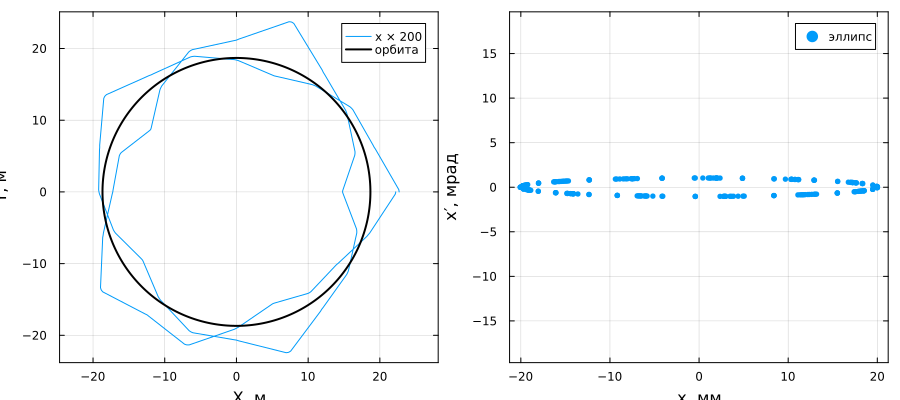

In [5]:
Ax = 20e-3
zB = init_canonical(S, dm, Ax, 0.0)
samp = sample_along(S, zB; nturns = 2)
scale = 200.0; R = S.C / 2pi
φs = samp.s ./ R
p1 = plot((R .+ scale .* samp.x) .* cos.(φs), (R .+ scale .* samp.x) .* sin.(φs),
          aspect_ratio = :equal, label = "x × $(Int(scale))", xlabel = "X, м", ylabel = "Y, м")
plot!(p1, R .* cos.(range(0, 2pi; length = 300)), R .* sin.(range(0, 2pi; length = 300)),
      lw = 2, color = :black, label = "орбита")
ZB = run_turns(z -> step_exact(S, z), zB, 200)
ux = [canonical_to_user(ZB[:, n], S.ref, S.C, S.h)[1] for n in 1:200]
uxp = [canonical_to_user(ZB[:, n], S.ref, S.C, S.h)[2] for n in 1:200]
p2 = scatter(ux .* 1e3, uxp .* 1e3, xlabel = "x, мм", ylabel = "x′, мрад",
             label = "эллипс", ms = 3, msw = 0, aspect_ratio = :equal)
plot(p1, p2, size = (900, 400))

**Вывод.** Бетатрон идёт поверх синхротрона. Поперечник на плане увеличен, иначе миллиметры на фоне периметра не видны.

![ring](../note/figs/fig_04_ring.png)
![ellipse](../note/figs/fig_04_ellipse.png)

## 5. Удлинение пути

**Вопрос.** На сколько бетатрон удлиняет путь, если полость включена?

Две частицы в одном кольце: без бетатрона и с ним. Рисунок — их разность, не прогон с $V=0$.

In [6]:
s0 = sample_along(S, z0; nturns = 3)
sX = sample_along(S, zB; nturns = 3)
Jx = cs_action(Ax, S.po.x)
LamX = formula_B_Lambda(S.C, Jx, S.xi.x[2], 0.0, 0.0)
plot(sX.s, (sX.L .- s0.L) .* 1e3, xlabel = "s, м", ylabel = "разность ΔL, мм",
     label = "две частицы, A_x = 20 мм", lw = 1.4)
plot!([0, 3S.C], [0, 3S.C * LamX] .* 1e3, ls = :dash, lw = 2, label = "Λ_x s")
@printf("Λ_x формулы = %.4e\n", LamX)

Λ_x формулы = 8.0832e-07


**Вывод.** Лишняя длина набирается с наклоном формулы. ВЧ включён: синхротронная часть вычтена разностью.

![path x](../note/figs/fig_05_path_x.png)
![path mean](../note/figs/fig_05_path_mean.png)

## 6. Бетатрон в $\delta_{\mathrm{eq}}$

**Вопрос.** На сколько сдвигается среднее $\delta$, если добавить бетатрон?

In [7]:
Ax10 = 10e-3; Nb = 1200
z10 = init_canonical(S, dm, Ax10, 0.0)
Z10 = run_turns(z -> step_exact(S, z), z10, Nb)
d10 = deltas_of(Z10)
Jx10 = cs_action(Ax10, S.po.x)
m1L = formula_delta_eq(S.pe, S.xi, S.C, dm, Jx10, 0.0)
plot(1:Nb, running_mean(d10) .* 1e6, xscale = :log10, xlabel = "N", ylabel = "⟨δ⟩ · 10⁶",
     label = "A_x = 10 мм", lw = 1.5)
hline!([m1 * 1e6], ls = :dash, lw = 2, label = "формула без Λ")
hline!([m1L * 1e6], ls = :dot, lw = 2, label = "формула с Λ")
@printf("сдвиг формулы от Λ: %.3e\n", m1L - m1)

сдвиг формулы от Λ: 3.786e-07


**Вывод.** Среднее садится на формулу с $\Lambda$, а не на формулу без него.

![lambda](../note/figs/fig_06_lambda.png)

## 7. Формула и произведение Ли

**Вопрос.** Собирает ли формула те же числа, которые уже лежат в произведении Ли?

Формула говорит: равновесный $\delta$ сдвигается на $2\pi\xi_x/(C\eta_0)$ на единицу горизонтального действия. Нормальная форма этих имён не использует.

In [8]:
dx_form = 2pi / S.C * S.xi.x[2] / S.pe.eta0
ds_form = -S.pe.eta1 * S.nf.sigma_delta_s^2 / S.pe.eta0
@printf("сдвиг на единицу Jx: формула %.6e,  NF %.6e,  отн. %.1e\n",
        dx_form, S.nf.d[1], S.nf.d[1] / dx_form - 1)
@printf("сдвиг на единицу Js: формула %.6e,  NF %.6e,  отн. %.1e\n",
        ds_form, S.nf.d[3], S.nf.d[3] / ds_form - 1)

сдвиг на единицу Jx: формула 1.466526e-01,  NF 1.466524e-01,  отн. -8.8e-07
сдвиг на единицу Js: формула 2.477064e-03,  NF 2.477064e-03,  отн. -1.1e-07


**Вывод.** Формула собрала те же числа, которые алгебра уже содержит.

![lie](../note/figs/fig_07_lie.png)

## 8. Тор

**Вопрос.** Что такое тор, по которому усредняется $\delta$?

Тор — все тройки фаз при фиксированных амплитудах. Один оборот ставит на него точку, долгий трекинг наматывает нитку. $\delta_{\mathrm{eq}}$ — среднее по поверхности, не точка, в которую частица приходит.

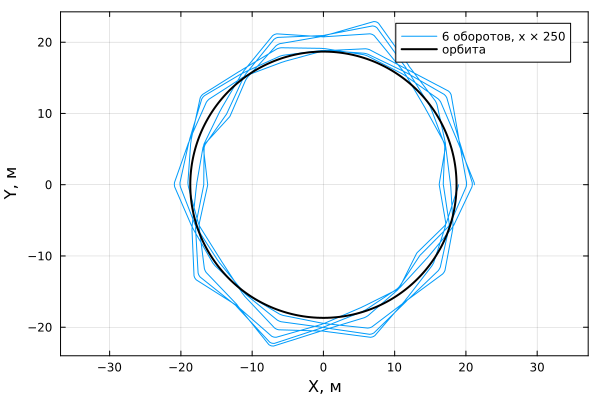

In [9]:
samp8 = sample_along(S, z10; nturns = 6)
sc = 250.0; R = S.C / 2pi
φ8 = samp8.s ./ R
plot((R .+ sc .* samp8.x) .* cos.(φ8), (R .+ sc .* samp8.x) .* sin.(φ8),
     aspect_ratio = :equal, label = "6 оборотов, x × $(Int(sc))",
     xlabel = "X, м", ylabel = "Y, м")
plot!(R .* cos.(range(0, 2pi; length = 300)), R .* sin.(range(0, 2pi; length = 300)),
      lw = 2, color = :black, label = "орбита")

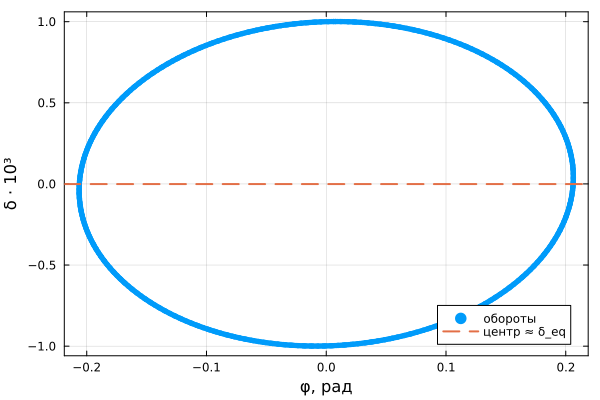

In [10]:
ph10 = phis_note_of(Z10, S)
scatter(ph10, d10 .* 1e3, xlabel = "φ, рад", ylabel = "δ · 10³", ms = 3, msw = 0,
        label = "обороты")
hline!([mean(d10) * 1e3], lw = 2, ls = :dash, label = "центр ≈ δ_eq")

Поверхность $(\theta_\beta,\theta_s)$ при $J_y=0$, цвет — $\delta$, нитка — точный интегратор (полный расчёт):

![torus ring](../note/figs/fig_08_torus_ring.png)
![synchrotron](../note/figs/fig_08_synchrotron.png)
![surface](../note/figs/fig_08_torus_surface.png)

**Вывод.** Полный тор трёхмерный: вторая бетатронная фаза на срезе не показана. Трекинг рисует одну нитку.

## 9. Усечённая карта и произведение Ли

**Вопрос.** Что портит полином степени 3: среднее $\delta$ или само движение?

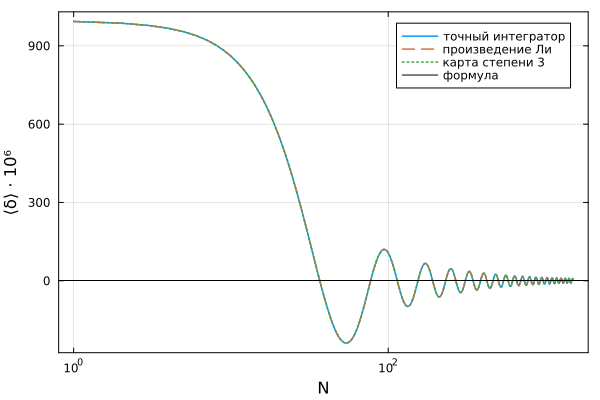

In [11]:
N9 = 1500
dM = deltas_of(run_turns(z -> step_map(S, z), z0, N9))
dL = deltas_of(run_turns(z -> step_lie(S, z), z0, N9))
dE = dlong[1:min(N9, length(dlong))]
plot(1:length(dE), running_mean(dE) .* 1e6, xscale = :log10, xlabel = "N",
     ylabel = "⟨δ⟩ · 10⁶", label = "точный интегратор", lw = 1.5)
plot!(1:N9, running_mean(dL) .* 1e6, ls = :dash, label = "произведение Ли", lw = 1.5)
plot!(1:N9, running_mean(dM) .* 1e6, ls = :dot, label = "карта степени 3", lw = 1.5)
hline!([m1 * 1e6], color = :black, label = "формула")

In [12]:
Na = 800
Zex = run_turns(z -> step_exact(S, z), z10, Na)
Zmp = run_turns(z -> step_map(S, z), z10, Na)
Jex = [cs_J_turn(Zex[:, n], S.po.x) for n in 1:Na]
Jmap = [cs_J_turn(Zmp[:, n], S.po.x) for n in 1:Na]
plot(1:Na, Jex .* 1e6, xlabel = "n", ylabel = "J_x · 10⁶", label = "точный интегратор", lw = 1.4)
plot!(1:Na, Jmap .* 1e6, label = "усечённая карта", lw = 1.4)
@printf("Jx интегратор %.4e, карта в конце %.4e\n", mean(Jex), mean(Jmap[end-50:end]))

Jx интегратор 2.5898e-06, карта в конце 2.5898e-06


В ячейке выше карта и интегратор считаются заново на каждом обороте в генераторе — это медленно. Действие на полном прогоне:

![mean](../note/figs/fig_09_mean.png)
![action](../note/figs/fig_09_action.png)
![symplectic](../note/figs/fig_09_symplectic.png)

**Вывод.** Среднее $\delta$ у трёх кривых рядом. На 10 мм уход действия карты ещё мал. Симплектичность карты портится с амплитудой.